In [1]:
import os
import mne
import torch
import warnings
warnings.filterwarnings(
    "ignore",
    message="This filename.*",
    category=RuntimeWarning,
)
from datasets import *
import numpy as np
from result_fig_meeg import *
from eois import *
from test_on_loso import *
import pandas as pd

In [2]:
models_names = ["visual_time_[None, None]_models_v", "auditory_time_[None, None]_models_v",
               "TMS_time_[-0.5, 0.5]_models_v", "TMS_strt_time_[-0.5, None]_models_v"]
model_datatypes = ['visual', 'auditory', 'TMS', 'TMS_st']
#test_datatypes = {'visual':['vis/checker','audio/300Hz'],'auditory':['audio/300Hz'], 'TMS':['TMS'], 'TMS_st':['TMS_st']}
test_datatypes = {'visual':['vis/checker', 'audio/300Hz'], 'auditory':['vis/checker', 'audio/300Hz'], 'TMS':['TMS'], 'TMS_st':['TMS_st']}
models_freqs = [np.arange(4.0, 30.0, 2.0), np.arange(4.0, 30.0, 2.0), np.arange(4.0, 40.0, 2.0), np.arange(4.0, 40.0, 2.0)]
pre_ends = [201, 201, 501, 501]
post_ends = [pre_end + 400 for pre_end in pre_ends] # 400 ms post-stim to test
path_to_models = os.path.join(os.getcwd(),"models")
rows = []

def ncycles_piecewise(freqs):
    n = np.empty_like(freqs, dtype=int)
    n[freqs < 6] = 3             # < 6 Hz → 3 cycles
    n[(freqs >= 6) & (freqs < 12)] = 4   # 6–10 Hz → 4 cycles
    n[(freqs >= 12) & (freqs < 20)] = 5  # 12–18 Hz → 5 cycles
    n[freqs >= 20] = 6           # ≥20 Hz → 6 cycles
    return n
    
models_n_cycles = [ncycles_piecewise(models_freqs[0]), ncycles_piecewise(models_freqs[1]), ncycles_piecewise(models_freqs[2]), ncycles_piecewise(models_freqs[3])]

for model_name, model_datatype, freqs, n_cycles, pre_end, post_end in zip(models_names, model_datatypes, models_freqs, models_n_cycles, pre_ends, post_ends):
    models_path = os.path.join(path_to_models, model_name)
    Xs = []
    for model_of_sub in os.listdir(models_path):
        if "final" not in model_of_sub:
            continue
        model_path = os.path.join(models_path, model_of_sub)
        subject = model_path.split("_")[-3]
        #print(subject)
        for test_datatype in test_datatypes[model_datatype]:
            row = test_subject(subject, model_path, test_datatype, model_datatype, freqs, pre_end, post_end, n_cycles, eps=1e-8)
            if row is not False:
                rows.append(row)
df = pd.DataFrame(rows)
df.to_pickle("models/results.pkl")
print("done")

done


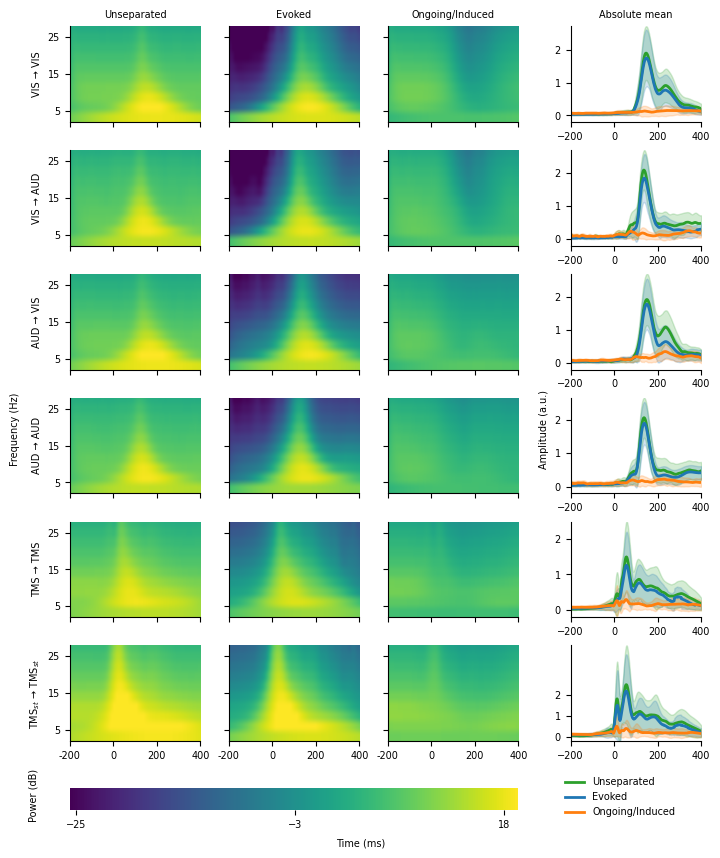

In [3]:
df = pd.read_pickle("results.pkl")
mapping = {
     'visual':   ['visual', 'auditory'],
    'auditory': ['visual', 'auditory'],
    'TMS':      ['TMS'],
    'TMS_st':   ['TMS_st'],
}
fig = plot_all_mappings(df, mapping, scale="db")
fig.savefig("fig_2_ahola.pdf", dpi=300)

In [4]:
import pandas as pd

# Load
df = pd.read_pickle("models/results.pkl")

# Metrics to summarize (keep only those present)
metric_map = {
    'ppc_x_post':  'PPC X post',
    'u_ppc_post': 'PPC U post',
    'e_ppc_post': 'PPC E post',
    'ppc_x_post_lo':  'PPC X post lo',
    'u_ppc_post_lo': 'PPC U post lo',
    'e_ppc_post_lo': 'PPC E post lo',
    'ppc_x_post_hi':  'PPC X post hi',
    'u_ppc_post_hi': 'PPC U post hi',
    'e_ppc_post_hi': 'PPC E post hi',
    'trial_reco_med': 'R² Trial',
    'evoked_reco':'R² Evoked',
}
metrics = [m for m in metric_map if m in df.columns]

# Coerce to numeric (handles numbers and strings like 'tensor(0.1066)')
for m in metrics:
    df[m] = pd.to_numeric(
        df[m].astype(str).str.replace(r'^\s*tensor\(|\)\s*$', '', regex=True),
        errors='coerce'
    )

# Group
g = df.groupby(['stimulation_type_train', 'stimulation_type_test'])

# Median and MAD
medians = g[metrics].median()
mads = g[metrics].agg(lambda s: (s - s.median()).abs().median())

# Subjects per group (unique subjects)
subjects = g['subject'].nunique()

# Simple label mapping
def short(x: str) -> str:
    s = str(x)
    if s.lower() == 'visual':   return 'VIS'
    if s.upper() == 'VIS':      return 'VIS'
    if s.lower() == 'auditory': return 'AUD'
    if s.upper() == 'AUD':      return 'AUD'
    if s == 'TMS-st':           return r'TMS\text{-}st'
    if s == 'TMS':              return 'TMS'
    return s

# Order columns VIS/VIS, VIS/AUD, AUD/VIS, AUD/AUD, TMS/TMS, TMS-st/TMS-st (if present)
order_map = {'VIS': 0, 'AUD': 1, 'TMS': 2, r'TMS\text{-}st': 3}
pairs = list(medians.index)
pairs_sorted = sorted(pairs, key=lambda p: (order_map.get(short(p[0]), 99), order_map.get(short(p[1]), 99)))

# Build wide table "$median \pm MAD$"
prec = 3
def fmt(m, d):
    return f"${m:.{prec}f} \\pm {d:.{prec}f}$"

col_names = [f"{short(tr)}/{short(te)}" for (tr, te) in pairs_sorted]
row_names = [metric_map[m] for m in metrics]
wide = pd.DataFrame(index=row_names, columns=col_names, dtype=object)

for tr, te in pairs_sorted:
    col = f"{short(tr)}/{short(te)}"
    for m in metrics:
        wide.loc[metric_map[m], col] = fmt(medians.loc[(tr, te), m], mads.loc[(tr, te), m])

# Add Subjects row at top
subjects_row = {f"{short(tr)}/{short(te)}": int(subjects.loc[(tr, te)]) for tr, te in pairs_sorted}
wide = pd.concat([pd.DataFrame([subjects_row], index=['Subjects']), wide], axis=0)

# LaTeX
wide.index.name = "Metric"
col_format = 'l' + 'c' * wide.shape[1]
latex_str = wide.to_latex(
    escape=False,
    column_format=col_format,
    index_names=True,
    multicolumn=False,
    multirow=False,
    caption=None,
    label="tab:ppc_r2_summary"
)

print(latex_str)


\begin{table}
\label{tab:ppc_r2_summary}
\begin{tabular}{lcccccc}
\toprule
 & VIS/VIS & VIS/AUD & AUD/VIS & AUD/AUD & TMS/TMS & TMS_st/TMS_st \\
Metric &  &  &  &  &  &  \\
\midrule
Subjects & 219 & 49 & 49 & 92 & 52 & 52 \\
PPC X post & $0.230 \pm 0.048$ & $0.220 \pm 0.032$ & $0.235 \pm 0.042$ & $0.211 \pm 0.040$ & $0.139 \pm 0.060$ & $0.178 \pm 0.062$ \\
PPC U post & $0.015 \pm 0.008$ & $0.019 \pm 0.016$ & $0.061 \pm 0.023$ & $0.014 \pm 0.014$ & $0.023 \pm 0.012$ & $0.024 \pm 0.011$ \\
PPC E post & $0.736 \pm 0.044$ & $0.716 \pm 0.047$ & $0.760 \pm 0.043$ & $0.796 \pm 0.034$ & $0.663 \pm 0.066$ & $0.706 \pm 0.066$ \\
PPC X post lo & $0.414 \pm 0.080$ & $0.434 \pm 0.063$ & $0.419 \pm 0.081$ & $0.410 \pm 0.074$ & $0.260 \pm 0.126$ & $0.309 \pm 0.117$ \\
PPC U post lo & $0.014 \pm 0.010$ & $0.023 \pm 0.031$ & $0.066 \pm 0.024$ & $0.015 \pm 0.019$ & $0.028 \pm 0.015$ & $0.034 \pm 0.019$ \\
PPC E post lo & $0.683 \pm 0.072$ & $0.655 \pm 0.074$ & $0.667 \pm 0.072$ & $0.699 \pm 0.064$ & $0.